In [1]:
# 09 - Merge - Farah vs Zaineb: a FAIR comparison of the two works, then the REAL merge, model by model
# PART 1 (this part): Zaineb's methods re-run on my protocol (all the 3681 clean wavs, the 3 folds of the first
#                     version of the notebooks)
# PART 2 (at the end): the real merge on the FINAL protocol (80% train part, the test set never used): Farah,
#                     Zaineb and merged candidates for each model -> the winners used by notebooks 02, 03, 04, 06
#
# Zaineb trained the same 4 models (SVM, decision tree, CNN, ResNet50) in her own repo, but with other data
# (3784 wavs: no cleaning, 858 abnormal), other features and other folds (split by patient).
# Her numbers can't be compared with mine directly. So here, I run HER methods on MY protocol:
#   - the same data: my 3681 clean wavs (the same cleaning rules as all my notebooks), read in the same order
#   - the same 3 folds: KFold(n_splits=3, shuffle=True, random_state=1), like notebooks 02, 03, 04, 06
#   - the same metrics: accuracy, precision, recall, f1 of the abnormal class (the sick hearts)
# My numbers come from MLflow (experiment audio_benchmark, the runs of notebooks 02, 03, 04, 06).
#
# Decision rule for each model (in this order): 1. it matches the project PDF, 2. it runs on my PC,
# 3. the highest mean validation RECALL of abnormal (then F1), 4. simple enough to explain.
# The decisions are written in MERGE_NOTES.md (repo root).

In [2]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"    # hide the TensorFlow info messages

import pickle
from glob import glob

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
import IPython.display as ipd

from sklearn.model_selection import KFold, GridSearchCV, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

import tensorflow as tf
import keras
from keras.models import Sequential
from keras.layers import Input, Conv2D, BatchNormalization, Activation, MaxPooling2D, Dropout
from keras.layers import GlobalAveragePooling2D, Dense
from keras.utils import to_categorical
from keras.applications.resnet50 import ResNet50

import mlflow

tf.get_logger().setLevel("ERROR")

In [3]:
# my folders (the same as in the other notebooks)
project_folder = "D:/MLOps_Project/"
ourdataset_folder = "D:/MLOps_Project/ourdataset/train/"


def load_data(file_name):
    with open(file_name, "rb") as f:
        return pickle.load(f)


def save_data(data, file_name):
    with open(file_name, "wb") as f:
        pickle.dump(data, f)


SR = 2000    # every wav at 2000 Hz, like all my notebooks

In [4]:
# ==================== 1. My clean wavs + Zaineb's features (72 numbers per wav) ====================
# Zaineb's features (her notebooks 02 and 03), computed on the WHOLE wav (no 5 s cut):
#   duration, SNR, mean and std of 20 Mel bands, mean and std of 13 MFCC, spectral centroid, zero-crossing rate
# Her settings: n_fft = 512, hop_length = 128, 20 Mel bands, 2000 Hz.
def signaltonoise(a, axis=0, ddof=0):
    a = np.asanyarray(a)
    m = a.mean(axis)
    sd = a.std(axis=axis, ddof=ddof)
    return np.where(sd == 0, 0, m / sd)


def zaineb_features(signal):
    duration = len(signal) / SR
    snr = float(signaltonoise(signal / max(np.max(np.abs(signal)), 1e-10)))
    S = librosa.feature.melspectrogram(y=signal, sr=SR, n_fft=512, hop_length=128, n_mels=20)
    S_DB = librosa.power_to_db(S, ref=np.max)
    mfcc = librosa.feature.mfcc(y=signal, sr=SR, n_mfcc=13, n_fft=512, hop_length=128, n_mels=20)
    centroid = librosa.feature.spectral_centroid(y=signal, sr=SR, n_fft=512, hop_length=128)
    zcr = librosa.feature.zero_crossing_rate(signal, frame_length=512, hop_length=128)
    return np.concatenate([[duration, snr], np.mean(S_DB, axis=1), np.std(S_DB, axis=1),
                           np.mean(mfcc, axis=1), np.std(mfcc, axis=1),
                           [np.mean(centroid), np.std(centroid), np.mean(zcr), np.std(zcr)]])


def zaineb_spectrogram(signal):
    # her CNN input: the middle 5 s (a shorter wav is repeated), 64 Mel bands, n_fft 512, hop 128 -> 64 x 79
    n = SR * 5
    if len(signal) < n:
        signal = np.tile(signal, int(np.ceil(n / len(signal))))[:n]
    else:
        start = (len(signal) - n) // 2
        signal = signal[start:start + n]
    S = librosa.feature.melspectrogram(y=signal, sr=SR, n_fft=512, hop_length=128, n_mels=64)
    return librosa.power_to_db(S, ref=np.max).astype("float32")


cache_file = project_folder + "merge_zaineb_features.data"
if os.path.exists(cache_file):
    files, y, X72, specs = load_data(cache_file)
else:
    files, labels, features, spectrograms = [], [], [], []
    for class_name in ["abnormal", "normal"]:                     # abnormal first, like all my notebooks
        for file in glob(ourdataset_folder + class_name + "/*.wav"):
            signal, rate = librosa.load(file, sr=SR)
            # my cleaning rules (the same in every notebook): too short, silent, saturated -> skipped
            too_short = len(signal) < 2 * SR
            silent = np.max(np.abs(signal)) < 0.001
            saturated = np.mean(np.abs(signal) >= 0.99) > 0.01
            if too_short or silent or saturated:
                continue
            files.append(os.path.basename(file))
            labels.append(1 if class_name == "abnormal" else 0)
            features.append(zaineb_features(signal))
            spectrograms.append(zaineb_spectrogram(signal))
    y = np.array(labels)
    X72 = np.array(features)
    specs = np.array(spectrograms)
    save_data((files, y, X72, specs), cache_file)

print(len(files), "clean wavs | normal:", np.sum(y == 0), "| abnormal:", np.sum(y == 1))
print("Zaineb's features:", X72.shape, "| Zaineb's spectrograms:", specs.shape)

# the same wavs in the same order as my caches? (my labels are saved by notebook 03)
my_labels = np.array(load_data(project_folder + "mfcc_features_tree_b.data"))
assert len(my_labels) == len(y) and np.all(my_labels == y), "not the same wavs / order as my notebooks!"
print("Same wavs and same order as my notebooks: OK")

3681 clean wavs | normal: 2855 | abnormal: 826
Zaineb's features: (3681, 72) | Zaineb's spectrograms: (3681, 64, 79)
Same wavs and same order as my notebooks: OK


In [5]:
# ==================== 2. My 3 folds + the metrics ====================
kfold = KFold(n_splits=3, shuffle=True, random_state=1)    # the SAME 3 folds as my notebooks 02, 03, 04, 06
folds = list(kfold.split(X72))


def metrics_of(y_true, y_pred):
    return {"accuracy": accuracy_score(y_true, y_pred),
            "precision": precision_score(y_true, y_pred),     # precision, recall, f1: of the abnormal class
            "recall": recall_score(y_true, y_pred),
            "f1": f1_score(y_true, y_pred)}


comparison = []    # 1 line per (model, method): the mean of the 3 folds


def add_result(model, method, fold_rows):
    table = pd.DataFrame(fold_rows)
    line = {"model": model, "method": method}
    for metric in ["accuracy", "precision", "recall", "f1"]:
        line[metric] = table[metric].mean()
    comparison.append(line)
    print(model, "-", method, ": recall = {:.3f} | f1 = {:.3f} | precision = {:.3f} | accuracy = {:.3f}".format(
        line["recall"], line["f1"], line["precision"], line["accuracy"]))

In [6]:
# ==================== 3. SVM: Zaineb's features (22 basic / 72 extended) and her GridSearch ====================
# basic = duration, SNR, mean of the 20 Mel bands (22) | extended = all 72
feature_sets = {"basic (22)": np.arange(22), "extended (72)": np.arange(72)}

for set_name in feature_sets:
    columns = feature_sets[set_name]
    rows = []
    for train_index, test_index in folds:
        model = make_pipeline(StandardScaler(), SVC(kernel="rbf", class_weight="balanced"))
        model.fit(X72[train_index][:, columns], y[train_index])
        rows.append(metrics_of(y[test_index], model.predict(X72[test_index][:, columns])))
    add_result("SVM", "Zaineb - rbf, " + set_name, rows)

# her tuned version: C and gamma chosen by GridSearchCV INSIDE the train part of each fold (inner 3 folds, F1)
rows = []
for train_index, test_index in folds:
    grid = {"svc__C": [1, 10, 100], "svc__gamma": ["scale", 0.01, 0.1]}
    search = GridSearchCV(make_pipeline(StandardScaler(), SVC(kernel="rbf", class_weight="balanced")), grid,
                          cv=KFold(n_splits=3, shuffle=True, random_state=1), scoring="f1", n_jobs=-1)
    search.fit(X72[train_index], y[train_index])
    rows.append(metrics_of(y[test_index], search.predict(X72[test_index])))
add_result("SVM", "Zaineb - rbf, extended (72), tuned C/gamma", rows)

SVM - Zaineb - rbf, basic (22) : recall = 0.883 | f1 = 0.653 | precision = 0.518 | accuracy = 0.789


SVM - Zaineb - rbf, extended (72) : recall = 0.887 | f1 = 0.702 | precision = 0.581 | accuracy = 0.831


SVM - Zaineb - rbf, extended (72), tuned C/gamma : recall = 0.795 | f1 = 0.737 | precision = 0.687 | accuracy = 0.872


In [7]:
# ==================== 4. Decision tree: Zaineb's features + her depth chosen inside each fold ====================
# Her method: for each fold, max_depth (1 to 15) is chosen by a 3-fold cross-validation on the TRAIN part only
# (F1 of abnormal), so the validation third is never used to choose the depth. I do the same with my 26 MFCC.
def choose_depth(X_train, y_train):
    inner = KFold(n_splits=3, shuffle=True, random_state=1)
    best_depth = 1
    best_f1 = -1
    for depth in range(1, 16):
        f1_list = []
        for inner_train, inner_val in inner.split(X_train):
            tree = DecisionTreeClassifier(max_depth=depth, class_weight="balanced", random_state=0)
            tree.fit(X_train[inner_train], y_train[inner_train])
            f1_list.append(f1_score(y_train[inner_val], tree.predict(X_train[inner_val])))
        if np.mean(f1_list) > best_f1:
            best_f1 = np.mean(f1_list)
            best_depth = depth
    return best_depth


X26 = np.array(load_data(project_folder + "mfcc_features_tree_a.data"))    # my 26 MFCC features (notebook 03)
for name, X in [("Zaineb - 72 features, depth chosen per fold", X72),
                ("Farah features (26 MFCC), depth chosen per fold", X26)]:
    rows = []
    depths = []
    for train_index, test_index in folds:
        depth = choose_depth(X[train_index], y[train_index])
        tree = DecisionTreeClassifier(max_depth=depth, class_weight="balanced", random_state=0)
        tree.fit(X[train_index], y[train_index])
        rows.append(metrics_of(y[test_index], tree.predict(X[test_index])))
        depths.append(depth)
    add_result("DecisionTree", name + " " + str(depths), rows)

DecisionTree - Zaineb - 72 features, depth chosen per fold [6, 5, 9] : recall = 0.863 | f1 = 0.656 | precision = 0.531 | accuracy = 0.797


DecisionTree - Farah features (26 MFCC), depth chosen per fold [6, 9, 5] : recall = 0.825 | f1 = 0.630 | precision = 0.515 | accuracy = 0.781


In [8]:
# ==================== 5. CNN: Zaineb's network on my folds ====================
# Her CNN: 64 x 79 spectrogram, 3 x (Conv2D + BatchNorm + ReLU + MaxPooling + Dropout 0.2), GlobalAveragePooling,
# Dense 64, softmax (2 classes), Adam. Training stops when the loss of a validation part (25% of the train part,
# never the validation third) stops going down for 12 epochs (EarlyStopping), at most 60 epochs.
def build_zaineb_cnn():
    model = Sequential()
    model.add(Input(shape=(64, 79, 1)))
    for filters in [16, 32, 64]:
        model.add(Conv2D(filters, (3, 3), padding="same"))
        model.add(BatchNormalization(momentum=0.9))
        model.add(Activation("relu"))
        model.add(MaxPooling2D((2, 2)))
        model.add(Dropout(0.2))
    model.add(GlobalAveragePooling2D())
    model.add(Dense(64, activation="relu"))
    model.add(Dropout(0.3))
    model.add(Dense(2, activation="softmax"))
    model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
    return model


def balanced_weights(labels):
    return {0: len(labels) / (2 * np.sum(labels == 0)), 1: len(labels) / (2 * np.sum(labels == 1))}


images = ((specs + 80) / 80).reshape(len(specs), 64, 79, 1)
rows = []
for train_index, test_index in folds:
    fit_index, stop_index = train_test_split(train_index, test_size=0.25, stratify=y[train_index], random_state=42)
    keras.utils.set_random_seed(42)
    model = build_zaineb_cnn()
    model.fit(images[fit_index], to_categorical(y[fit_index], 2), batch_size=32, epochs=60,
              validation_data=(images[stop_index], to_categorical(y[stop_index], 2)),
              class_weight=balanced_weights(y[fit_index]), verbose=0,
              callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=12, restore_best_weights=True)])
    y_pred = np.argmax(model.predict(images[test_index], verbose=0), axis=1)
    rows.append(metrics_of(y[test_index], y_pred))
add_result("CNN", "Zaineb - BatchNorm + GlobalAveragePooling + softmax, early stopping", rows)

CNN - Zaineb - BatchNorm + GlobalAveragePooling + softmax, early stopping : recall = 0.798 | f1 = 0.705 | precision = 0.632 | accuracy = 0.850


In [9]:
# ==================== 6. ResNet50 transfer learning: Zaineb's version on my folds ====================
# Her version: the grey spectrogram (64 x 79, 0-1) -> x 255 -> copied in 3 channels -> 128 x 128 -> ImageNet mean
# colour removed -> frozen ResNet50 (2048 numbers) -> head Dropout + Dense 256 + Dropout + sigmoid, Adam 0.001,
# early stopping on a validation part of the train part (patience 10, at most 50 epochs).
base_model = ResNet50(weights="imagenet", include_top=False, pooling="avg", input_shape=(128, 128, 3))
base_model.trainable = False

embeddings = []
for start in range(0, len(images), 64):
    batch = np.repeat(images[start:start + 64] * 255, 3, axis=-1)                  # grey -> 3 channels
    batch = tf.image.resize(batch, (128, 128)).numpy()                             # 64 x 79 -> 128 x 128
    batch = batch - np.array([103.939, 116.779, 123.68])                           # ImageNet mean colour
    embeddings.append(base_model.predict(batch, verbose=0))
embeddings = np.concatenate(embeddings)
print("ResNet50 embeddings:", embeddings.shape)


def build_zaineb_head():
    head = Sequential()
    head.add(Input(shape=(2048,)))
    head.add(Dropout(0.3))
    head.add(Dense(256, activation="relu"))
    head.add(Dropout(0.3))
    head.add(Dense(1, activation="sigmoid"))
    head.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001), loss="binary_crossentropy", metrics=["accuracy"])
    return head


rows = []
for train_index, test_index in folds:
    fit_index, stop_index = train_test_split(train_index, test_size=0.25, stratify=y[train_index], random_state=42)
    keras.utils.set_random_seed(42)
    head = build_zaineb_head()
    head.fit(embeddings[fit_index], y[fit_index], batch_size=32, epochs=50,
             validation_data=(embeddings[stop_index], y[stop_index]),
             class_weight=balanced_weights(y[fit_index]), verbose=0,
             callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)])
    y_pred = (head.predict(embeddings[test_index], verbose=0).ravel() > 0.5).astype(int)
    rows.append(metrics_of(y[test_index], y_pred))
add_result("ResNet50", "Zaineb - grey 128 x 128, head Dense 256, early stopping", rows)

ResNet50 embeddings: (3681, 2048)


ResNet50 - Zaineb - grey 128 x 128, head Dense 256, early stopping : recall = 0.757 | f1 = 0.740 | precision = 0.723 | accuracy = 0.881


In [10]:
# ==================== 7. My results on the same folds (from MLflow, experiment audio_benchmark) ====================
mlflow.set_tracking_uri("http://localhost:5000")
runs = mlflow.search_runs(experiment_names=["audio_benchmark"], order_by=["start_time DESC"])
runs = runs[runs["metrics.mean_recall"].notna()]       # only the main runs (not the fold runs)

my_runs = {"SVM": "svm_rbf_5s", "DecisionTree": "decision_tree_gini_depth10", "CNN": "cnn", "ResNet50": "resnet50"}
my_methods = {"SVM": "Farah - rbf, Mel 30 bands flattened (5 s)", "DecisionTree": "Farah - 26 MFCC, gini, depth 10",
              "CNN": "Farah - Conv 16/32/64 + Flatten + Dense 32 + sigmoid, 20 epochs",
              "ResNet50": "Farah - magma 224 x 224, head BN + Dense 128, 30 epochs"}
for model in my_runs:
    run = runs[runs["tags.mlflow.runName"] == my_runs[model]].iloc[0]    # the latest run with this name
    comparison.append({"model": model, "method": my_methods[model],
                       "accuracy": run["metrics.mean_accuracy"], "precision": run["metrics.mean_precision"],
                       "recall": run["metrics.mean_recall"], "f1": run["metrics.mean_f1"]})

table = pd.DataFrame(comparison).sort_values(["model", "recall"], ascending=[True, False]).reset_index(drop=True)
ipd.display(table.round(3))

,model,method,accuracy,precision,recall,f1
0,CNN,Farah - Conv 16/32/64 + Flatten + Dense 32 + s...,0.778,0.510,0.925,0.655
1,CNN,Zaineb - BatchNorm + GlobalAveragePooling + so...,0.850,0.632,0.798,0.705
2,DecisionTree,"Zaineb - 72 features, depth chosen per fold [6...",0.797,0.531,0.863,0.656
3,DecisionTree,"Farah features (26 MFCC), depth chosen per fol...",0.781,0.515,0.825,0.630
4,DecisionTree,"Farah - 26 MFCC, gini, depth 10",0.810,0.559,0.718,0.629
5,ResNet50,"Farah - magma 224 x 224, head BN + Dense 128, ...",0.889,0.730,0.800,0.763
6,ResNet50,"Zaineb - grey 128 x 128, head Dense 256, early...",0.881,0.723,0.757,0.740
7,SVM,"Zaineb - rbf, extended (72)",0.831,0.581,0.887,0.702
8,SVM,"Zaineb - rbf, basic (22)",0.789,0.518,0.883,0.653
9,SVM,"Farah - rbf, Mel 30 bands flattened (5 s)",0.791,0.521,0.829,0.639


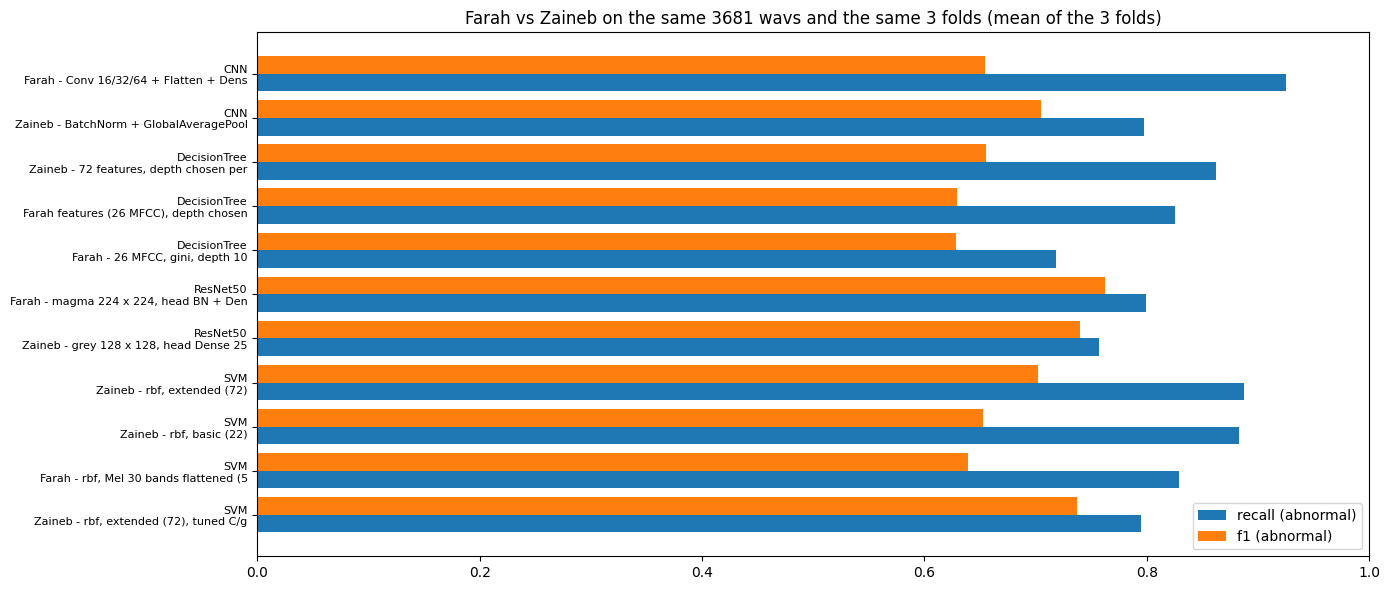

In [11]:
# ONE figure: recall and F1 of abnormal for every method, grouped by model
plt.figure(figsize=(14, 6))
names = [row["model"] + "\n" + row["method"][:38] for _, row in table.iterrows()]
x = np.arange(len(table))
plt.barh(x + 0.2, table["recall"], height=0.4, label="recall (abnormal)")
plt.barh(x - 0.2, table["f1"], height=0.4, label="f1 (abnormal)")
plt.yticks(x, names, fontsize=8)
plt.xlim(0, 1)
plt.gca().invert_yaxis()
plt.title("Farah vs Zaineb on the same 3681 wavs and the same 3 folds (mean of the 3 folds)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(project_folder + "models plots/merge_farah_vs_zaineb.png")
plt.show()

In [1]:
# ==================== PART 2 - The REAL merge, on the final protocol (the same as notebooks 02 to 07) ====================
# Part 1 (above) only compared the 2 works. Here, for each model, we try Farah's version, Zaineb's version and MERGED
# versions (the best ideas of both), with the protocol of the final notebooks:
#   - the 80% train part only (the 20% test set of notebook 01 is NOT used to choose anything)
#   - the same 3 validation folds: KFold(n_splits=3, shuffle=True, random_state=1)
#   - the same metrics (abnormal = the positive class)
# The rule to replace the current version (the first candidate) by another candidate:
#   - a higher validation RECALL (if it loses more than 0.01 of F1, it is a trade-off: we keep the higher recall,
#     the rule of the PDF, and we write the trade-off in MERGE_NOTES.md)
#   - or a higher F1 without losing more than 0.01 of recall
# Accuracy alone would be misleading: a model that says "normal" more often gets a higher accuracy (77% of the wavs
# are normal) but misses more sick hearts.
# The results are saved in "models plots/merge_results.json": notebooks 02, 03, 04 and 06 show them in their
# "Merge: Farah vs Zaineb" cell and train only the winner. (This part is independent from Part 1.)
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import json
import time
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import IPython.display as ipd

from sklearn.model_selection import KFold, GridSearchCV, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, fbeta_score, make_scorer

import keras
from keras.models import Sequential
from keras.layers import Input, Conv2D, BatchNormalization, Activation, MaxPooling2D, Dropout, Flatten
from keras.layers import GlobalAveragePooling2D, Dense
from keras.optimizers import Adam
from keras.utils import to_categorical

project_folder = "D:/MLOps_Project/"
plots_folder = "D:/MLOps_Project/models plots/"


def load_data(file_name):
    with open(file_name, "rb") as f:
        return pickle.load(f)


# all the caches of the notebooks: the same 3681 clean wavs in the same order (checked with the names)
files = np.array(load_data(project_folder + "cnn_files.data"))
y = np.array(load_data(project_folder + "cnn_labels.data"))
assert list(files) == load_data(project_folder + "tree_files.data") == load_data(project_folder + "svm_files.data")
zaineb_files, zaineb_y, zaineb_X72, zaineb_specs = load_data(project_folder + "merge_zaineb_features.data")
assert list(files) == list(zaineb_files) and np.all(y == zaineb_y)

X_mfcc26 = np.array(load_data(project_folder + "mfcc_features_tree_a.data"))           # Farah, notebook 03
X_72 = np.array(load_data(project_folder + "extended_features_72.data"))                # Zaineb's 72 features
X_mel = np.array(load_data(project_folder + "mel_features_svm_a.data"))                 # Farah, notebook 02
cnn_images = ((np.array(load_data(project_folder + "cnn_spectrograms.data")) + 80) / 80).reshape(-1, 40, 157, 1)
zaineb_images = ((zaineb_specs + 80) / 80).reshape(-1, 64, 79, 1)                       # Zaineb's 64 x 79
tl_features = np.array(load_data(project_folder + "tl_features_ResNet50.data"))         # notebook 06

# the fixed test set (notebook 01): put aside
with open(project_folder + "splits/test_files.json") as f:
    split = json.load(f)
is_test = np.isin(files, split["test_files"])
train = ~is_test
y_train = y[train]
kfold = KFold(n_splits=3, shuffle=True, random_state=1)
folds = list(kfold.split(np.zeros(np.sum(train))))
class_weight = {0: len(y_train) / (2 * np.sum(y_train == 0)), 1: len(y_train) / (2 * np.sum(y_train == 1))}
print("train part:", np.sum(train), "wavs | 3 folds | class_weight:", class_weight)


def metrics_of(y_true, y_pred):
    return {"accuracy": accuracy_score(y_true, y_pred), "precision": precision_score(y_true, y_pred),
            "recall": recall_score(y_true, y_pred), "f1": f1_score(y_true, y_pred)}


def mean_of(fold_rows):
    line = {}
    for metric in ["recall", "f1", "precision", "accuracy"]:
        line[metric] = round(float(np.mean([row[metric] for row in fold_rows])), 3)
    return line


def replaces(candidate, current):
    # the rule of the merge (see above)
    if candidate["recall"] > current["recall"]:
        return True
    if candidate["f1"] > current["f1"] and candidate["recall"] >= current["recall"] - 0.01:
        return True
    return False


def choose(candidates):
    winner = candidates[0]
    for candidate in candidates[1:]:
        if replaces(candidate, winner):
            winner = candidate
    for candidate in candidates:
        candidate["kept"] = candidate is winner
        # trade-off: more recall but more than 0.01 of F1 lost (or the opposite) compared with the winner
        candidate["trade_off"] = (not candidate["kept"]) and (candidate["f1"] > winner["f1"] + 0.01)
    return winner


merge_results = {}


def show(model, candidates, winner):
    table = pd.DataFrame(candidates)[["name", "from", "recall", "f1", "precision", "accuracy", "kept", "trade_off"]]
    ipd.display(table)
    print("Winner for", model, ":", winner["name"])
    merge_results[model] = {"candidates": candidates, "winner": winner["key"]}

train part: 2944 wavs | 3 folds | class_weight: {0: np.float64(0.6447656592203241), 1: np.float64(2.226928895612708)}


In [2]:
# ==================== SVM (notebook 02) ====================
# (a) Zaineb's 72 features, rbf, default C and gamma = the current notebook 02 (it already won against Farah's Mel)
# (b) the same + C and gamma chosen by GridSearchCV INSIDE each training fold, with the F2 score
#     (F2 = an F-score where the recall counts twice as much as the precision)
# (c) Zaineb's 72 features + Farah's Mel features (2 s), side by side, rbf, default C and gamma
def svm_folds(X, tuned=False):
    rows = []
    chosen = []
    X = X[train]
    for train_index, val_index in folds:
        model = make_pipeline(StandardScaler(), SVC(kernel="rbf", class_weight="balanced"))
        if tuned:
            grid = {"svc__C": [1, 10, 100], "svc__gamma": ["scale", 0.01, 0.1]}
            model = GridSearchCV(model, grid, scoring=make_scorer(fbeta_score, beta=2),
                                 cv=KFold(n_splits=3, shuffle=True, random_state=1), n_jobs=-1)
        model.fit(X[train_index], y_train[train_index])
        if tuned:
            chosen.append(model.best_params_)
        rows.append(metrics_of(y_train[val_index], model.predict(X[val_index])))
    return rows, chosen


svm_candidates = []
rows, chosen = svm_folds(X_72)
svm_candidates.append(dict(key="extended72", name="72 features, rbf, default C/gamma", **{"from": "Zaineb"},
                           **mean_of(rows)))
rows, chosen = svm_folds(X_72, tuned=True)
print("C and gamma chosen in each fold (F2):", chosen)
svm_candidates.append(dict(key="extended72_tuned_f2", name="72 features, rbf, C/gamma tuned with F2 in each fold",
                           **{"from": "merged"}, **mean_of(rows)))
rows, chosen = svm_folds(np.hstack([X_72, X_mel]))
svm_candidates.append(dict(key="extended72_plus_mel", name="72 features + Mel 2 s (552 numbers), rbf",
                           **{"from": "merged"}, **mean_of(rows)))
show("SVM", svm_candidates, choose(svm_candidates))

C and gamma chosen in each fold (F2): [{'svc__C': 1, 'svc__gamma': 'scale'}, {'svc__C': 1, 'svc__gamma': 'scale'}, {'svc__C': 1, 'svc__gamma': 'scale'}]


,name,from,recall,f1,precision,accuracy,kept,trade_off
0,"72 features, rbf, default C/gamma",Zaineb,0.894,0.705,0.582,0.832,True,False
1,"72 features, rbf, C/gamma tuned with F2 in eac...",merged,0.894,0.705,0.582,0.832,False,False
2,"72 features + Mel 2 s (552 numbers), rbf",merged,0.845,0.676,0.564,0.818,False,False


Winner for SVM : 72 features, rbf, default C/gamma


In [3]:
# ==================== Decision tree (notebook 03) ====================
# The criterion and the max_depth are chosen with the 3 folds of the train part (Zaineb's idea: never with the test),
# with 2 ways of choosing:
#   - "F1 rule": the highest validation F1 (the current notebook 03)
#   - "recall rule": among the settings that lose at most 0.01 of F1 compared with the best F1, the highest recall
#     (the strict version of the merge rule: without it, a 1-question tree that says "abnormal" very often would win)
# (b) is Zaineb's own method: the depth chosen again INSIDE each fold by an inner cross-validation (F1).
def tree_search(X):
    rows = []
    for criterion in ["gini", "entropy"]:
        for depth in range(1, 16):
            fold_rows = []
            for train_index, val_index in folds:
                tree = DecisionTreeClassifier(criterion=criterion, max_depth=depth, class_weight="balanced",
                                              random_state=0)
                tree.fit(X[train][train_index], y_train[train_index])
                fold_rows.append(metrics_of(y_train[val_index], tree.predict(X[train][val_index])))
            rows.append(dict(criterion=criterion, max_depth=depth, **mean_of(fold_rows)))
    return pd.DataFrame(rows)


def f1_rule(search):
    return search.loc[search["f1"].idxmax()]


def recall_rule(search):
    good = search[search["f1"] >= search["f1"].max() - 0.01]
    return good.sort_values(["recall", "f1"], ascending=False).iloc[0]


def zaineb_nested(X):
    rows = []
    depths = []
    for train_index, val_index in folds:
        X_tr, y_tr = X[train][train_index], y_train[train_index]
        best_depth, best_f1 = 1, -1
        for depth in range(1, 16):
            scores = []
            for inner_train, inner_val in KFold(n_splits=3, shuffle=True, random_state=1).split(X_tr):
                tree = DecisionTreeClassifier(max_depth=depth, class_weight="balanced", random_state=0)
                tree.fit(X_tr[inner_train], y_tr[inner_train])
                scores.append(f1_score(y_tr[inner_val], tree.predict(X_tr[inner_val])))
            if np.mean(scores) > best_f1:
                best_depth, best_f1 = depth, np.mean(scores)
        tree = DecisionTreeClassifier(max_depth=best_depth, class_weight="balanced", random_state=0)
        tree.fit(X_tr, y_tr)
        rows.append(metrics_of(y_train[val_index], tree.predict(X[train][val_index])))
        depths.append(best_depth)
    return rows, depths


def one_setting(X, criterion, depth):
    fold_rows = []
    for train_index, val_index in folds:
        tree = DecisionTreeClassifier(criterion=criterion, max_depth=depth, class_weight="balanced", random_state=0)
        tree.fit(X[train][train_index], y_train[train_index])
        fold_rows.append(metrics_of(y_train[val_index], tree.predict(X[train][val_index])))
    return mean_of(fold_rows)


search26 = tree_search(X_mfcc26)
search72 = tree_search(X_72)
tree_candidates = [dict(key="mfcc26_gini_depth10", name="26 MFCC, gini, depth 10 (Farah's original)",
                        **{"from": "Farah"}, criterion="gini", max_depth=10, features="26 MFCC",
                        **one_setting(X_mfcc26, "gini", 10))]
rows, depths = zaineb_nested(X_72)
tree_candidates.append(dict(key="extended72_nested", name="72 features, depth chosen inside each fold " + str(depths),
                            **{"from": "Zaineb"}, criterion="gini", max_depth=None, features="72 extended",
                            **mean_of(rows)))
for set_name, search, X in [("26 MFCC", search26, X_mfcc26), ("72 extended", search72, X_72)]:
    for rule_name, rule in [("F1 rule", f1_rule), ("recall rule", recall_rule)]:
        best = rule(search)
        key = ("mfcc26" if set_name == "26 MFCC" else "extended72") + "_" + rule_name.split()[0].lower()
        tree_candidates.append(dict(key=key, name=set_name + ", " + rule_name + ": " + best["criterion"] + " depth "
                                    + str(int(best["max_depth"])), **{"from": "merged"}, criterion=best["criterion"],
                                    max_depth=int(best["max_depth"]), features=set_name,
                                    **one_setting(X, best["criterion"], int(best["max_depth"]))))
show("DecisionTree", tree_candidates, choose(tree_candidates))

,name,from,recall,f1,precision,accuracy,kept,trade_off
0,"26 MFCC, gini, depth 10 (Farah's original)",Farah,0.688,0.624,0.571,0.814,False,False
1,"72 features, depth chosen inside each fold [11...",Zaineb,0.770,0.651,0.570,0.815,False,False
2,"26 MFCC, F1 rule: entropy depth 10",merged,0.737,0.654,0.588,0.825,False,False
3,"26 MFCC, recall rule: entropy depth 9",merged,0.767,0.650,0.565,0.814,False,False
4,"72 extended, F1 rule: gini depth 8",merged,0.778,0.660,0.574,0.820,False,False
5,"72 extended, recall rule: entropy depth 7",merged,0.820,0.657,0.550,0.807,True,False


Winner for DecisionTree : 72 extended, recall rule: entropy depth 7


In [4]:
# ==================== CNN (notebook 04) ====================
# (a) Farah's CNN: 3 x (Conv2D + MaxPooling), Flatten, Dense 32, Dropout 0.5, 20 epochs (the current notebook 04)
# (b) Zaineb's CNN: 64 x 79 spectrogram, 3 x (Conv2D + BatchNorm + ReLU + MaxPooling + Dropout), GlobalAveragePooling,
#     Dense 64, softmax, early stopping on 25% of the training fold (at most 60 epochs)
# (c) MERGED: Farah's 3 blocks + BatchNormalization after each Conv2D (Zaineb) + class_weight + EarlyStopping
#     (restore the best weights) on an inner 10% of the training fold (never the validation fold), at most 40 epochs
# (d) like (c) with GlobalAveragePooling2D instead of Flatten (Zaineb's idea)
def build_farah_cnn():
    model = Sequential([Input(shape=(40, 157, 1)),
                        Conv2D(16, (3, 3), activation="relu"), MaxPooling2D((2, 2)),
                        Conv2D(32, (3, 3), activation="relu"), MaxPooling2D((2, 2)),
                        Conv2D(64, (3, 3), activation="relu"), MaxPooling2D((2, 2)),
                        Flatten(), Dense(32, activation="relu"), Dropout(0.5), Dense(1, activation="sigmoid")])
    model.compile(optimizer=Adam(learning_rate=0.001), loss="binary_crossentropy", metrics=["accuracy"])
    return model


def build_merged_cnn(global_pooling):
    model = Sequential()
    model.add(Input(shape=(40, 157, 1)))
    for filters in [16, 32, 64]:
        model.add(Conv2D(filters, (3, 3)))
        model.add(BatchNormalization())
        model.add(Activation("relu"))
        model.add(MaxPooling2D((2, 2)))
    if global_pooling:
        model.add(GlobalAveragePooling2D())
    else:
        model.add(Flatten())
    model.add(Dense(32, activation="relu"))
    model.add(Dropout(0.5))
    model.add(Dense(1, activation="sigmoid"))
    model.compile(optimizer=Adam(learning_rate=0.001), loss="binary_crossentropy", metrics=["accuracy"])
    return model


def build_zaineb_cnn():
    model = Sequential()
    model.add(Input(shape=(64, 79, 1)))
    for filters in [16, 32, 64]:
        model.add(Conv2D(filters, (3, 3), padding="same"))
        model.add(BatchNormalization(momentum=0.9))
        model.add(Activation("relu"))
        model.add(MaxPooling2D((2, 2)))
        model.add(Dropout(0.2))
    model.add(GlobalAveragePooling2D())
    model.add(Dense(64, activation="relu"))
    model.add(Dropout(0.3))
    model.add(Dense(2, activation="softmax"))
    model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
    return model


def keras_folds(images, build, early_stopping, max_epochs, inner_size=0.1, patience=8, softmax=False):
    rows = []
    epochs_used = []
    X = images[train]
    for train_index, val_index in folds:
        keras.utils.set_random_seed(0)
        model = build()
        fit_index = train_index
        options = {}
        if early_stopping:
            fit_index, stop_index = train_test_split(train_index, test_size=inner_size, stratify=y_train[train_index],
                                                     random_state=0)
            stop_y = to_categorical(y_train[stop_index], 2) if softmax else y_train[stop_index]
            options["validation_data"] = (X[stop_index], stop_y)
            options["callbacks"] = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience,
                                                                  restore_best_weights=True)]
        fit_y = to_categorical(y_train[fit_index], 2) if softmax else y_train[fit_index]
        history = model.fit(X[fit_index], fit_y, epochs=max_epochs, batch_size=32, class_weight=class_weight,
                            verbose=0, **options)
        epochs_used.append(len(history.history["loss"]))
        probabilities = model.predict(X[val_index], verbose=0)
        if softmax:
            y_pred = np.argmax(probabilities, axis=1)
        else:
            y_pred = (probabilities.ravel() > 0.5).astype(int)
        rows.append(metrics_of(y_train[val_index], y_pred))
    return rows, epochs_used


cnn_candidates = []
start = time.time()
rows, used = keras_folds(cnn_images, build_farah_cnn, early_stopping=False, max_epochs=20)
cnn_candidates.append(dict(key="farah", name="Farah: Conv + MaxPool, Flatten, Dense 32, 20 epochs",
                           **{"from": "Farah"}, **mean_of(rows)))
rows, used = keras_folds(zaineb_images, build_zaineb_cnn, early_stopping=True, max_epochs=60, inner_size=0.25,
                         patience=12, softmax=True)
cnn_candidates.append(dict(key="zaineb", name="Zaineb: BatchNorm + GAP + softmax, early stopping " + str(used),
                           **{"from": "Zaineb"}, **mean_of(rows)))
rows, used = keras_folds(cnn_images, lambda: build_merged_cnn(False), early_stopping=True, max_epochs=40)
cnn_candidates.append(dict(key="merged_flatten", name="merged: + BatchNorm + early stopping, Flatten " + str(used),
                           **{"from": "merged"}, **mean_of(rows)))
rows, used = keras_folds(cnn_images, lambda: build_merged_cnn(True), early_stopping=True, max_epochs=40)
cnn_candidates.append(dict(key="merged_gap", name="merged: + BatchNorm + early stopping, GAP " + str(used),
                           **{"from": "merged"}, **mean_of(rows)))
print("CNN candidates trained in {:.0f} min".format((time.time() - start) / 60))
show("CNN", cnn_candidates, choose(cnn_candidates))

D:\MLOps_Project\venv\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


CNN candidates trained in 20 min


,name,from,recall,f1,precision,accuracy,kept,trade_off
0,"Farah: Conv + MaxPool, Flatten, Dense 32, 20 e...",Farah,0.938,0.628,0.472,0.750,True,False
1,"Zaineb: BatchNorm + GAP + softmax, early stopp...",Zaineb,0.668,0.690,0.715,0.865,False,True
2,"merged: + BatchNorm + early stopping, Flatten ...",merged,0.534,0.411,0.364,0.773,False,False
3,"merged: + BatchNorm + early stopping, GAP [22,...",merged,0.692,0.660,0.639,0.838,False,True


Winner for CNN : Farah: Conv + MaxPool, Flatten, Dense 32, 20 epochs


In [5]:
# ==================== Transfer learning ResNet50 (notebook 06): the ImageNet features are cached -> fast ====================
# (a) Farah's head: BatchNorm + Dense 128 + Dropout 0.5, Adam 0.0001, 30 epochs (the current notebook 06)
# (b) Farah's head + Zaineb's early stopping (inner 10% of the training fold, restore the best weights, at most 60 epochs)
# (c) like (b) with Dense 256 (Zaineb's size)
def build_head(units):
    head = Sequential([Input(shape=(2048,)), BatchNormalization(), Dense(units, activation="relu"), Dropout(0.5),
                       Dense(1, activation="sigmoid")])
    head.compile(optimizer=Adam(learning_rate=0.0001), loss="binary_crossentropy", metrics=["accuracy"])
    return head


tl_candidates = []
rows, used = keras_folds(tl_features, lambda: build_head(128), early_stopping=False, max_epochs=30)
tl_candidates.append(dict(key="farah", name="Farah: BN + Dense 128 + Dropout, 30 epochs", **{"from": "Farah"},
                          **mean_of(rows)))
rows, used = keras_folds(tl_features, lambda: build_head(128), early_stopping=True, max_epochs=60, patience=10)
tl_candidates.append(dict(key="early_stopping_128", name="merged: Dense 128 + early stopping " + str(used),
                          **{"from": "merged"}, **mean_of(rows)))
rows, used = keras_folds(tl_features, lambda: build_head(256), early_stopping=True, max_epochs=60, patience=10)
tl_candidates.append(dict(key="early_stopping_256", name="merged: Dense 256 + early stopping " + str(used),
                          **{"from": "merged"}, **mean_of(rows)))
show("ResNet50", tl_candidates, choose(tl_candidates))

,name,from,recall,f1,precision,accuracy,kept,trade_off
0,"Farah: BN + Dense 128 + Dropout, 30 epochs",Farah,0.789,0.748,0.713,0.881,False,False
1,"merged: Dense 128 + early stopping [29, 35, 29]",merged,0.780,0.729,0.687,0.870,False,False
2,"merged: Dense 256 + early stopping [23, 24, 29]",merged,0.793,0.746,0.704,0.879,True,False


Winner for ResNet50 : merged: Dense 256 + early stopping [23, 24, 29]


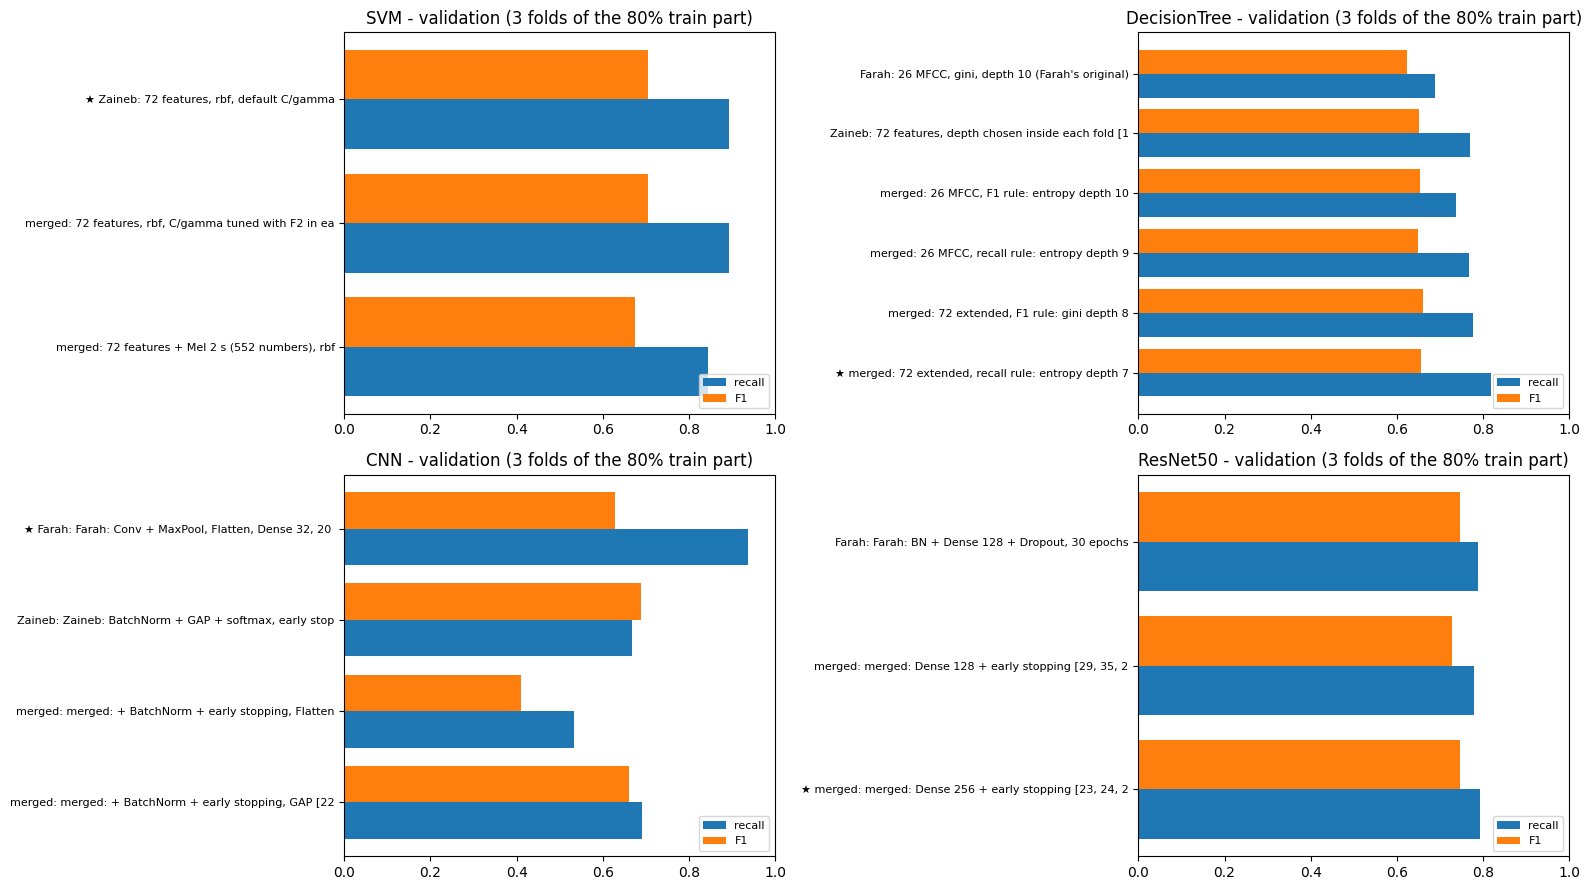

SVM -> extended72
DecisionTree -> extended72_recall
CNN -> farah
ResNet50 -> early_stopping_256


In [6]:
# ==================== The winners, saved for the notebooks 02, 03, 04, 06 ====================
with open(plots_folder + "merge_results.json", "w") as f:
    json.dump(merge_results, f, indent=1)

plt.figure(figsize=(16, 9))
place = 1
for model in merge_results:
    table = pd.DataFrame(merge_results[model]["candidates"])
    plt.subplot(2, 2, place)
    x = np.arange(len(table))
    plt.barh(x + 0.2, table["recall"], height=0.4, label="recall")
    plt.barh(x - 0.2, table["f1"], height=0.4, label="F1")
    labels = []
    for _, row in table.iterrows():
        labels.append(("★ " if row["kept"] else "") + row["from"] + ": " + row["name"][:45])
    plt.yticks(x, labels, fontsize=8)
    plt.xlim(0, 1)
    plt.gca().invert_yaxis()
    plt.title(model + " - validation (3 folds of the 80% train part)")
    plt.legend(loc="lower right", fontsize=8)
    place = place + 1
plt.tight_layout()
plt.savefig(plots_folder + "merge_candidates.png")
plt.show()
for model in merge_results:
    print(model, "->", merge_results[model]["winner"])